### Stage 02 — Build and prune gene trees for CAFA-training root HOGs

1. **Identify root HOGs containing training proteins.** Scan the original FastOMA OrthoXML and record each root HOG containing $\geq 1$ CAFA-training protein, including proteins in nested groups.

2. **Extract complete root HOGs.** Pass the selected root HOG IDs to Irene’s `orthoxml_subset.py` to create a new OrthoXML file containing all proteins and nested groups from each selected HOG.

3. **Generate one gene tree per root HOG.** Convert the subset with Irene’s `to-nhx --encode-levels` workflow. Verify the root HOG IDs, protein tips, and event annotations against the XML.

4. **Identify OMA sisters on the unpruned trees.** Use ETE to identify OMA leaves that share a mapped NCBI taxon and an immediate speciation-like parent with a CAFA-training leaf. Apply the reference notebook’s selection rule when multiple OMA leaves qualify. Retain all training leaves and OMA sisters under duplication parents.

5. **Prune leaves and collapse unary nodes.** Remove each selected OMA leaf once, then remove all CAFA-test leaves. Discard empty branches and collapse every node with exactly one child, including unary roots. Preserve the remaining multifurcations.

6. **Separate singletons and validate the final trees.** Record root HOGs with $n_{\mathrm{tips}} = 1$ separately. Reload the final trees and verify that each has $n_{\mathrm{tips}} \geq 2$, contains no CAFA-test leaves, and has no unary nodes. Account for every CAFA-training protein.

In [5]:
import os
from pathlib import Path

os.environ["WP1_ROOT"] = str(Path.home() / "evomics_projects/saschabrown/workpackage1")

### Open the original FastOMA OrthoXML

Run in a local kernel with the versions in `environments/stage02_filtering_ete.yml`. Set `WP1_ROOT` to the workpackage directory before launching Jupyter. The code below uses the laptop Desktop location when the variable is unset. The extraction uses Stage 02's `OMA_orthoxml` download and the pinned converter in `local_config/irene_tree_reference.*/orthoxml_tools_src`. All outputs go into a new Stage 02 results directory.


In [10]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path

from lxml import etree


#change wp1_root to  work on cluster

wp1_root = Path(os.environ.get("WP1_ROOT", Path.home() / "Desktop" / "workpackage1")).expanduser()

os.environ["WP1_ROOT"] = str(wp1_root)

orthoxml_path = (
    wp1_root
    / "HOGprop_validation_project/analysis/01_fastoma/results"
    / "20261105_101624_7305523/FastOMA_HOGs.orthoxml"
)

with orthoxml_path.open("rb") as xml_file:
    _, root = next(etree.iterparse(xml_file, events=("start",)))
    print("Opened:", orthoxml_path.resolve())
    print("Root element:", etree.QName(root).localname)
    print("Version:", root.get("version"))

Opened: /faststorage/project/evomics_projects/saschabrown/HOGprop_validation_project/fastoma_output/20261105_101624_7305523/FastOMA_HOGs.orthoxml
Root element: orthoXML
Version: 0.5


We scan the FastOMA OrthoXML and collect the gene IDs of CAFA-training proteins (protId ending in _train). For each root HOG, we check whether any descendant geneRef matches a training gene ID, including those in nested groups. We record each matching root HOG ID once. Irene’s script uses this list to extract the complete HOGs before pruning.

In [11]:
print((wp1_root / "local_config/orthoxml-tools-src/cli.py").is_file())

True


In [12]:
from lxml import etree
from tqdm.auto import tqdm

train_gene_ids = set()
selected_root_hogs = []
total_root_hogs = 0
active_root = None
has_training_protein = False

with orthoxml_path.open("rb") as xml_file, tqdm.wrapattr(
    xml_file,
    "read",
    total=orthoxml_path.stat().st_size,
    desc="Scanning OrthoXML",
    bytes=True,
) as reader:
    for event, elem in etree.iterparse(reader, events=("start", "end")):
        tag = etree.QName(elem).localname
        parent = elem.getparent()

        if event == "start":
            if tag == "orthologGroup" and etree.QName(parent).localname == "groups":
                active_root = elem
                total_root_hogs += 1
                has_training_protein = False
            continue

        if tag == "gene" and elem.get("protId", "").endswith("_train"):
            train_gene_ids.add(elem.attrib["id"])

        elif tag == "geneRef" and active_root is not None:
            if elem.attrib["id"] in train_gene_ids:
                has_training_protein = True

        elif elem is active_root:
            if has_training_protein:
                selected_root_hogs.append(elem.attrib["id"])
            active_root = None

        # Release processed elements to keep memory usage low.
        elem.clear()
        while elem.getprevious() is not None:
            del parent[0]

print(f"CAFA-training gene IDs in the XML: {len(train_gene_ids):,}")
print(f"Total root HOGs:                   {total_root_hogs:,}")
print(f"Root HOGs with ≥1 training gene:   {len(selected_root_hogs):,}")
print("First five selected IDs:", selected_root_hogs[:5])

Scanning OrthoXML:   0%|          | 0/4272204008 [00:00<?, ?it/s]

CAFA-training gene IDs in the XML: 82,334
Total root HOGs:                   826,375
Root HOGs with ≥1 training gene:   29,660
First five selected IDs: ['HOG:0000001_1', 'HOG:0000005_2784', 'HOG:0000006_2736', 'HOG:0000036_14614', 'HOG:0000087_8122']


In [13]:
import subprocess
import sys
from pathlib import Path
from tempfile import mkdtemp

stage = wp1_root / "HOGprop_validation_project/analysis/02_fastoma_output_processing"
irene_script = stage / "OMA_orthoxml" / "orthoxml_subset.py"

results_dir = stage / "results"
results_dir.mkdir(exist_ok=True)
output_dir = Path(mkdtemp(prefix="train_orthoxml_", dir=results_dir))

# Irene's script expects one root HOG ID per line, with no header.
hog_list = output_dir / "train_root_hog_ids.txt"
hog_list.write_text("\n".join(selected_root_hogs) + "\n", encoding="utf-8")

# -i: original OrthoXML   -t: root HOG IDs to keep   -o: output OrthoXML
train_orthoxml = output_dir / "cafa_train_unpruned.orthoxml"
print(f"Extracting {len(selected_root_hogs):,} complete root HOGs…", flush=True)

subprocess.run(
    [
        sys.executable, str(irene_script),
        "-i", str(orthoxml_path),
        "-t", str(hog_list),
        "-o", str(train_orthoxml),
    ],
    check=True,
)

print(f"Saved {train_orthoxml.stat().st_size / 1e9:.2f} GB")
train_orthoxml

Extracting 29,660 complete root HOGs…
Number of hogs to keep 29660
Saved 2.26 GB


PosixPath('/home/saschabrown/evomics_projects/saschabrown/workpackage1/HOGprop_validation_project/analysis/02_fastoma_output_processing/results/train_orthoxml_cv7d77ik/cafa_train_unpruned.orthoxml')

### Extract the complete training HOGs

The earlier cell identifies the roots. Here we independently regenerate the census and collect **every** gene reference within those roots for Irene’s filter. The two selections must agree. Each run gets its own results directory. The plot shows how many roots contain training proteins and how training proteins are distributed across selected roots.

In [14]:
import subprocess
import sys
from pathlib import Path
from tempfile import mkdtemp

# Use the notebook kernel and the converter linked under WP1_ROOT on each machine.
input_xml = Path(train_orthoxml)
converter_src = wp1_root / "local_config" / "orthoxml-tools-src"
converter = converter_src / "cli.py"

# Write this run's trees to a fresh folder beside the filtered XML.
tree_dir = Path(mkdtemp(prefix="unpruned_trees_", dir=input_xml.parent))
print(f"Writing unpruned trees to {tree_dir}", flush=True)

# Convert each root HOG into one annotated Newick tree.
subprocess.run(
    [
        sys.executable, str(converter), "to-nhx",
        "--infile", str(input_xml),
        "--outdir", str(tree_dir),
        "--encode-levels",      # Include taxonomic levels in the NHX annotations.
        "--xref-tag", "id",     # Label each protein tip with its XML gene ID.
    ],
    check=True,
)


Writing unpruned trees to /home/saschabrown/evomics_projects/saschabrown/workpackage1/HOGprop_validation_project/analysis/02_fastoma_output_processing/results/train_orthoxml_cv7d77ik/unpruned_trees_z20xd7ha


CompletedProcess(args=['/home/saschabrown/miniforge3/envs/fastoma/bin/python', '/home/saschabrown/evomics_projects/saschabrown/workpackage1/local_config/orthoxml-tools-src/cli.py', 'to-nhx', '--infile', '/home/saschabrown/evomics_projects/saschabrown/workpackage1/HOGprop_validation_project/analysis/02_fastoma_output_processing/results/train_orthoxml_cv7d77ik/cafa_train_unpruned.orthoxml', '--outdir', '/home/saschabrown/evomics_projects/saschabrown/workpackage1/HOGprop_validation_project/analysis/02_fastoma_output_processing/results/train_orthoxml_cv7d77ik/unpruned_trees_z20xd7ha', '--encode-levels', '--xref-tag', 'id'], returncode=0)

### Select sisters using etee 4
Underneath is the original species tree for the test HOG underneath. Here the red is showing the orignal species tree now this is shown here we have to think about how to incooporate branch lengths. But i think in the end it does not matter

![](<attachment:Screenshot From 2026-11-19 11-43-56.png>)
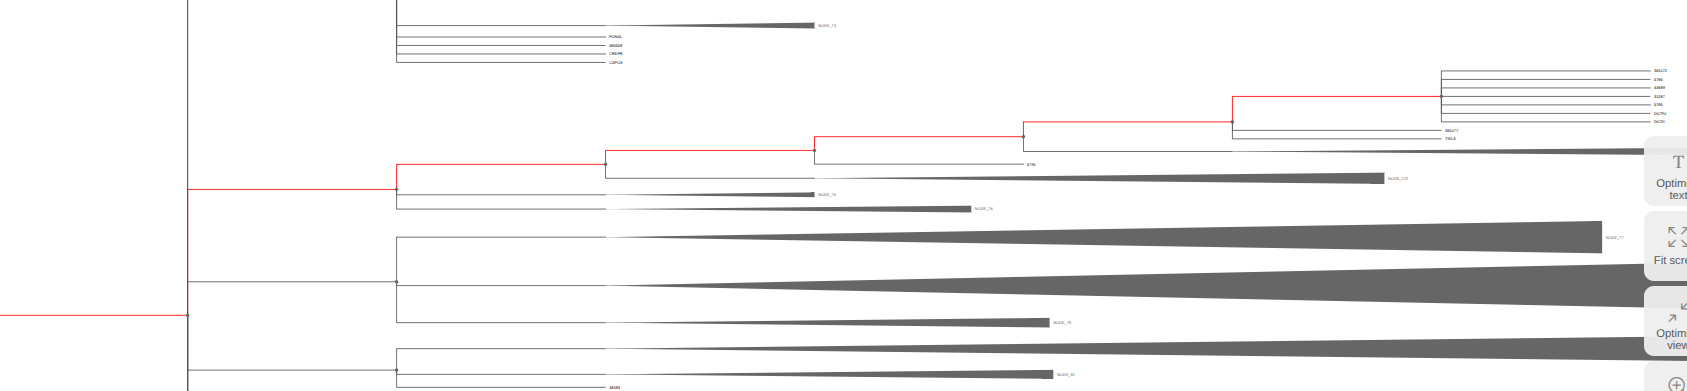

![Screenshot From 2026-11-19 11-45-05.png](<attachment:Screenshot From 2026-11-19 11-45-05.png>)
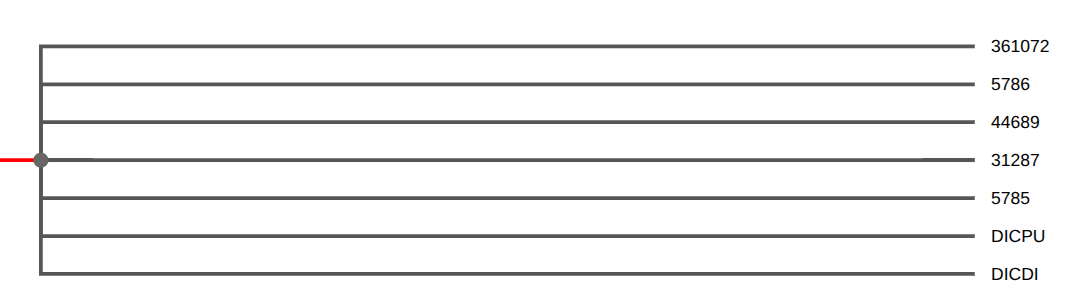

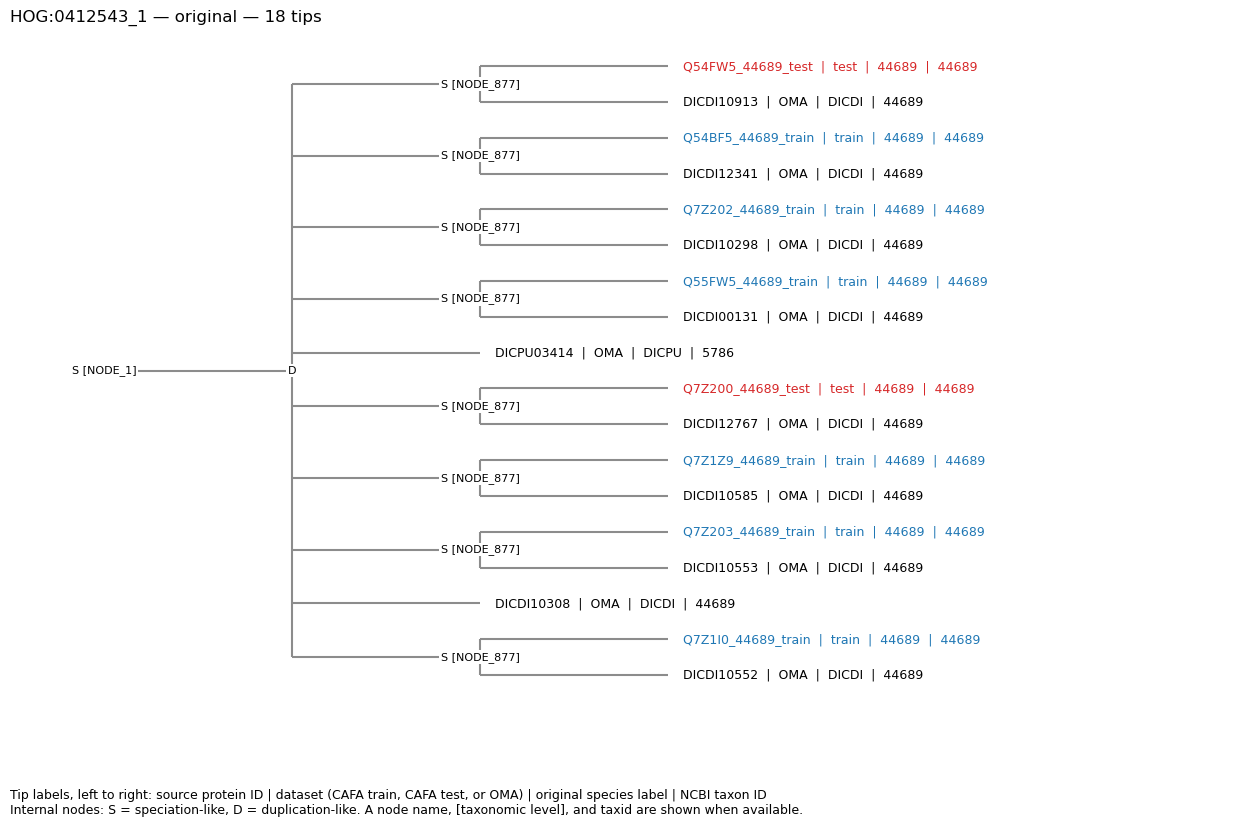

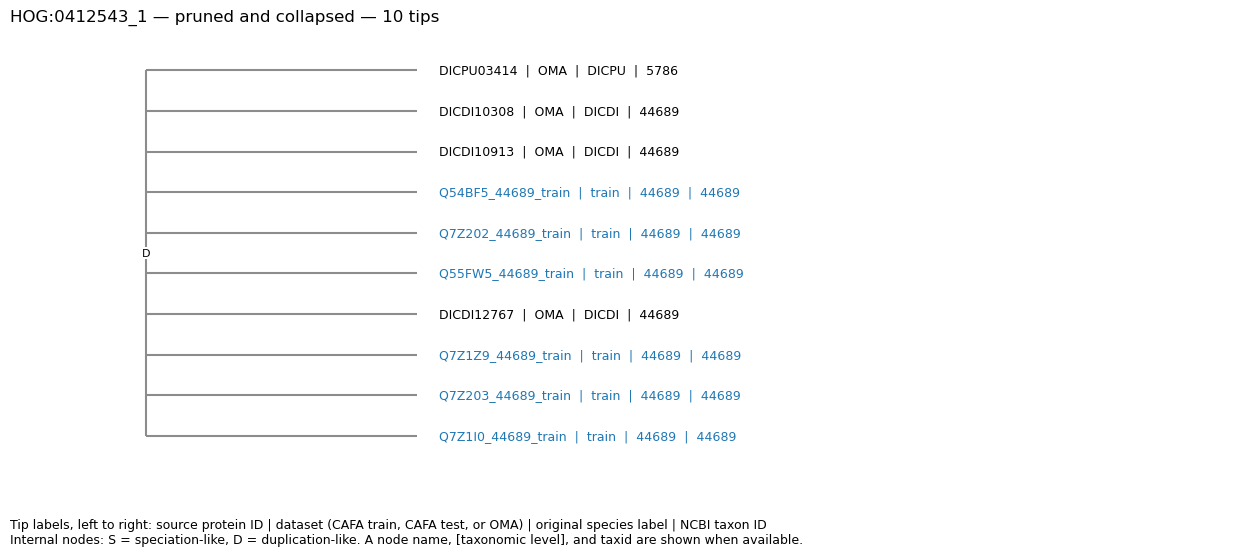

HOG:0412543_1 — keep
Protein leaves: 18 → 10
Unary nodes collapsed: 9


,xml_gene_id,protId,ncbi_taxid,reason
0,5638002965,Q54FW5_44689_test,44689,CAFA test
1,10187012341,DICDI12341,44689,OMA sister of same-species CAFA train
2,10187010298,DICDI10298,44689,OMA sister of same-species CAFA train
3,10187000131,DICDI00131,44689,OMA sister of same-species CAFA train
4,5638002378,Q7Z200_44689_test,44689,CAFA test
5,10187010585,DICDI10585,44689,OMA sister of same-species CAFA train
6,10187010553,DICDI10553,44689,OMA sister of same-species CAFA train
7,10187010552,DICDI10552,44689,OMA sister of same-species CAFA train


In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from ete4 import Tree
from lxml import etree


def load_tree(tree_dir, hog_id):
    """Load one of Irene's NHX-annotated Newick trees into ETE."""
    tree_file = Path(tree_dir) / f"tree_{hog_id}.nwk"
    return Tree(tree_file.read_text(), parser=1)


def add_leaf_information(tree, orthoxml_file, mapping_file):
    """Add protId, source and ncbi_taxid to each leaf of the supplied tree."""
    leaves = list(tree.leaves())
    wanted_ids = {leaf.name for leaf in leaves}

    # Match each numeric FastOMA leaf name to its source protein ID.
    protein_ids = {}
    gene_tag = "{http://orthoXML.org/2011/}gene"

    with Path(orthoxml_file).open("rb") as xml_file:
        for _, gene in etree.iterparse(xml_file, events=("end",), tag=gene_tag):
            gene_id = gene.get("id")

            if gene_id in wanted_ids:
                protein_ids[gene_id] = gene.attrib["protId"]
                if len(protein_ids) == len(wanted_ids):
                    break

            # Release gene records already read from the large XML file.
            gene.clear()
            while gene.getprevious() is not None:
                del gene.getparent()[0]

    missing = wanted_ids - protein_ids.keys()
    if missing:
        raise ValueError(f"Tree leaf IDs missing from the OrthoXML: {sorted(missing)}")

    # Map OMA species codes such as DICDI to the taxon IDs used by CAFA.
    mapping = pd.read_csv(mapping_file, sep="\t", dtype=str)
    oma_taxids = dict(zip(mapping["oma_code"], mapping["ncbi_taxid"]))

    for leaf in leaves:
        protein_id = protein_ids[leaf.name]
        species = leaf.props["S"]

        if species.isdigit():
            # CAFA example: Q7Z200_44689_test → source "test", taxon "44689".
            source = protein_id.rsplit("_", 1)[-1]
            if source not in {"train", "test"}:
                raise ValueError(f"Unexpected CAFA protein label: {protein_id}")
            taxid = species
        else:
            # OMA example: DICDI12767 → source "OMA", species code "DICDI".
            source = "OMA"
            taxid = oma_taxids.get(species, "unmapped")

        leaf.add_prop("protId", protein_id)
        leaf.add_prop("source", source)
        leaf.add_prop("ncbi_taxid", taxid)

    return tree


def plot_tree(tree, title):
    """Plot an ETE tree with compact tip labels and annotated internal nodes."""
    colors = {"train": "tab:blue", "test": "tab:red", "OMA": "black"}
    events = {"0>1": "S", "1>0": "D"}
    leaves = list(tree.leaves())

    # Assign one row per tip and one horizontal step per nesting level.
    y = {leaf: i for i, leaf in enumerate(reversed(leaves))}
    x = {tree: 0}
    for node in tree.traverse("preorder"):
        for child in node.children:
            x[child] = x[node] + 1

    fig, ax = plt.subplots(figsize=(13, max(5, 0.38 * len(leaves) + 2)))

    for node in tree.traverse("postorder"):
        if node.is_leaf:
            source = node.props["source"]
            label = (
                f"{node.props['protId']}  |  {source}  |  "
                f"{node.props['S']}  |  {node.props['ncbi_taxid']}"
            )
            ax.text(
                x[node] + 0.08, y[node], label,
                va="center", fontsize=9, color=colors[source],
            )
            continue

        # Draw the branches connecting this internal node to its children.
        child_rows = [y[child] for child in node.children]
        y[node] = (min(child_rows) + max(child_rows)) / 2
        ax.vlines(x[node], min(child_rows), max(child_rows), color="0.55")
        for child in node.children:
            ax.hlines(y[child], x[node], x[child], color="0.55")

        # Read each annotation from this internal node, when present.
        props = node.props
        event = props.get("Ev")
        parts = []
        if event:
            parts.append(events.get(event, event))
        if node.name:
            parts.append(node.name)
        if props.get("S"):
            parts.append(f"[{props['S']}]")
        if props.get("T"):
            parts.append(f"taxid={props['T']}")

        if parts:
            ax.text(
                x[node], y[node], " ".join(parts),
                ha="center", va="center", fontsize=8,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
            )

    ax.set_xlim(-0.5, max(x.values()) + 3)
    ax.set_ylim(-1, len(leaves))
    ax.set_title(f"{title} — {len(leaves)} tips", loc="left")
    ax.axis("off")

    fig.text(
        0.04, 0.03,
        "Tip labels, left to right: source protein ID | dataset (CAFA train, CAFA test, or OMA) "
        "| original species label | NCBI taxon ID\n"
        "Internal nodes: S = speciation-like, D = duplication-like. "
        "A node name, [taxonomic level], and taxid are shown when available.",
        fontsize=9, va="bottom",
    )
    fig.subplots_adjust(left=0.04, right=0.98, top=0.92, bottom=0.15)
    plt.show()




def prune_cafa_oma(tree):
    """Return a pruned ETE tree and a record of the pruning decisions."""
    pruned_tree = deepcopy(tree)
    to_remove = {}
    ambiguous = []

    for leaf in pruned_tree.leaves():
        source = leaf.props["source"]

        # Rule 1. Remove every CAFA test leaf, regardless of its sisters.
        if source == "test":
            to_remove[leaf] = "CAFA test"
            continue

        # Rule 2. For a training leaf, inspect its direct sisters only
        # when their shared parent is annotated as speciation-like.
        if source != "train":
            continue

        parent = leaf.up
        if parent is None or parent.props.get("Ev") != "0>1":
            continue

        taxid = leaf.props["ncbi_taxid"]
        if not taxid or taxid == "unmapped":
            continue

        oma_sisters = [
            sister
            for sister in parent.children
            if sister.is_leaf
            and sister.props["source"] == "OMA"
            and sister.props["ncbi_taxid"] == taxid
        ]

        if len(oma_sisters) == 1:
            to_remove[oma_sisters[0]] = "OMA sister of same-species CAFA train"

        elif len(oma_sisters) > 1:
            ambiguous.append({
                "train_protId": leaf.props["protId"],
                "ncbi_taxid": taxid,
                "oma_protIds": [sister.props["protId"] for sister in oma_sisters],
            })

    # Record each selected tip, then cut its branch from the tree.
    removed = []
    for leaf, reason in to_remove.items():
        removed.append({
            "xml_gene_id": leaf.name,
            "protId": leaf.props["protId"],
            "ncbi_taxid": leaf.props["ncbi_taxid"],
            "reason": reason,
        })
        leaf.detach()

    return pruned_tree, removed, ambiguous



def prune_and_collapse(tree):
    """Prune CAFA/OMA tips, then collapse unary nodes in the resulting tree."""
    # Remember which nodes were genuine gene tips before pruning.
    original_tip_ids = {leaf.name for leaf in tree.leaves()}

    # The pruning function already makes a copy of the input tree.
    pruned_tree, removed, ambiguous = prune_cafa_oma(tree)
    collapsed = 0

    # Postorder visits children before their parents.
    # Make the list first because we will change the topology as we go.
    for node in list(pruned_tree.traverse("postorder")):
        if node.is_leaf and node.name in original_tip_ids:
            continue

        # If all children were pruned, remove the empty internal node.
        if not node.children:
            if node.is_root:
                pruned_tree = None
            else:
                node.detach()
            continue

        # A node with two or more children is still a branching point.
        if len(node.children) > 1:
            continue

        # Exactly one child remains.
        if node.is_root:
            # The only child becomes the new root.
            pruned_tree = node.children[0].detach()
        else:
            # Connect the child to its grandparent. Disable automatic
            # cleanup so we can inspect and count each unary node ourselves.
            node.delete(prevent_nondicotomic=False)

        collapsed += 1

    return pruned_tree, removed, ambiguous, collapsed

from copy import deepcopy  # Used by your existing prune_cafa_oma() function.


def process_hog(tree_dir, hog_id, orthoxml_file, mapping_file, *, plot=False):
    """Process one root HOG and return (final_tree, report)."""

    # Load the original tree and attach protein IDs, sources, and taxon IDs.
    tree = load_tree(tree_dir, hog_id)
    tree = add_leaf_information(tree, orthoxml_file, mapping_file)

    if plot:
        plot_tree(tree, f"{hog_id} — original")

    # prune_and_collapse() calls prune_cafa_oma() internally.
    pruned_tree, removed, ambiguous, collapsed = prune_and_collapse(tree)

    # Count surviving protein leaves and exclude singleton or empty HOGs.
    n_remaining = 0 if pruned_tree is None else sum(1 for _ in pruned_tree.leaves())
    final_tree = pruned_tree if n_remaining >= 2 else None

    if plot and pruned_tree is not None:
        title = "pruned and collapsed" if n_remaining >= 2 else "excluded singleton"
        plot_tree(pruned_tree, f"{hog_id} — {title}")

    report = {
        "hog_id": hog_id,
        "kept": final_tree is not None,
        "original_proteins": sum(1 for _ in tree.leaves()),
        "remaining_proteins": n_remaining,
        "removed_proteins": len(removed),
        "collapsed_unary_nodes": collapsed,
        "removed": pd.DataFrame(
            removed, columns=["xml_gene_id", "protId", "ncbi_taxid", "reason"]
        ),
        "ambiguous": pd.DataFrame(
            ambiguous, columns=["train_protId", "ncbi_taxid", "oma_protIds"]
        ),
    }
    return final_tree, report

mapping_file = wp1_root / "HOGprop_validation_project" / "irene_cafa_oma_fasta_pairs.tsv"

final_tree, report = process_hog(
    tree_dir=tree_dir,
    hog_id="HOG:0412543_1",
    orthoxml_file=train_orthoxml,
    mapping_file=mapping_file,
    plot=True,
)

print(f"{report['hog_id']} — {'keep' if report['kept'] else 'skip'}")
print(f"Protein leaves: {report['original_proteins']} → {report['remaining_proteins']}")
print(f"Unary nodes collapsed: {report['collapsed_unary_nodes']}")

display(report["removed"])
if not report["ambiguous"].empty:
    display(report["ambiguous"])

### Export the pruned HOGs

The single-HOG example above uses `process_hog()`. For the cohort, index the filtered OrthoXML gene registry and the species mapping once. Load each original tree with `load_tree()` and apply the same `prune_and_collapse()` to its annotated leaves.

1. Sort the original IDs. Record the outcome for every input tree, including singletons.
2. Enumerate the retained trees from one in sorted order. The notebook calls Irene’s external `OrthoXMLBuilder` for each HOG with the assigned cohort-wide ID. Processing one tree at a time avoids loading all annotated trees into the converter at once.
3. Keep original numeric gene references and copy their original protein IDs and species records from the filtered XML. For each surviving speciation-like node, take its taxonomic level from the NHX S annotation. For a duplication at the root, Irene’s converter adds an outer orthologGroup for XML serialization.
4. Write one `pruned.nhx` and one `members.tsv` per retained HOG in ranges of 5,000 new IDs. The run-level `hog_id_map.tsv` maps original IDs to new IDs. The `hog_manifest.tsv` also includes HOGs excluded from export.
5. Use the membership tables on GenomeDK for FASTA extraction, then align sequences and estimate branch lengths in Stage 03.


In [16]:
import re
from tempfile import TemporaryDirectory


def hog_folder(output_root, new_hog_id):
    """Build the per-HOG path from the root ID assigned by Irene's converter."""
    match = re.fullmatch(r"HOG:([0-9]+)", new_hog_id)
    if match is None or int(match[1]) < 1:
        raise ValueError(f"Expected a positive exported root HOG ID, got {new_hog_id!r}")

    number = int(match[1])
    first = ((number - 1) // 5000) * 5000 + 1
    last = first + 4999
    return Path(output_root) / f"{first:08d}-{last:08d}" / f"HOG_{match[1]}"


def write_hog_folder(output_root, new_hog_id, final_tree, report):
    """Save one retained process_hog result after matching its exported XML ID."""
    if final_tree is None:
        return None

    folder = hog_folder(output_root, new_hog_id)
    folder.parent.mkdir(parents=True, exist_ok=True)
    members = pd.DataFrame([
        {
            "new_hog_id": new_hog_id,
            "original_hog_id": report["hog_id"],
            "xml_gene_id": leaf.name,
            "protId": leaf.props["protId"],
            "source": leaf.props["source"],
            "species_label": leaf.props["S"],
            "ncbi_taxid": leaf.props["ncbi_taxid"],
        }
        for leaf in final_tree.leaves()
    ])

    # Publish the folder after both files are ready.
    with TemporaryDirectory(dir=folder.parent) as temp:
        staged = Path(temp) / folder.name
        staged.mkdir()
        members.to_csv(staged / "members.tsv", sep="\t", index=False)
        nhx = final_tree.write(parser=1, props=["Ev", "S", "T", "protId", "source", "ncbi_taxid"],
                               format_root_node=True)
        (staged / "pruned.nhx").write_text(nhx + "\n")
        staged.rename(folder)

    return {
        "original_hog_id": report["hog_id"],
        "new_hog_id": new_hog_id,
        "remaining_proteins": len(members),
        "folder": str(folder.relative_to(output_root)),
    }


In [17]:
from concurrent.futures import ProcessPoolExecutor
from multiprocessing import get_context
from tempfile import mkdtemp
from xml.etree import ElementTree as ET
import csv
import sys
import dendropy

def export_one_hog(job):
    old_id, ordinal = job
    tree = load_tree(input_trees, old_id)
    for leaf in tree.leaves():
        protein, species = gene_registry[leaf.name]
        if species != leaf.props["S"]:
            raise ValueError((old_id, leaf.name, species))
        source = protein.rsplit("_", 1)[-1] if species.isdigit() else "OMA"
        if source not in {"test", "train", "OMA"}:
            raise ValueError(protein)
        leaf.props.update(protId=protein, source=source,
                          ncbi_taxid=species if species.isdigit() else taxids.get(species, "unmapped"))
    final, removed, ambiguous, collapsed = prune_and_collapse(tree)
    n = len(final) if final is not None else 0
    row = dict(original_hog_id=old_id, original_tips=len(tree), remaining_proteins=n,
               removed_test=sum(x["reason"] == "CAFA test" for x in removed),
               removed_oma=sum(x["reason"] != "CAFA test" for x in removed),
               ambiguous=len(ambiguous), collapsed=collapsed, new_hog_id="", folder="")
    if n < 2:
        return row
    # This intermediate uses source order. Assign consecutive retained IDs in the parent.
    stage_file = work / f"{ordinal}.nhx"
    stage_file.write_text(final.write(parser=1, props=["Ev","S","T","protId","source","ncbi_taxid"],
                                      format_root_node=True))
    return row

def convert_retained(job):
    ordinal, row = job
    path = work / f"{ordinal}.nhx"
    final = Tree(path.read_text(), parser=1)
    new_id = row["new_hog_id"]
    entry = write_hog_folder(out / "hogs", new_id, final, {"hog_id":row["original_hog_id"]})
    # Use Irene's converter per tree. Preserve the original numeric registry keys
    # and supply the cohort-wide root ID to her LOFT numbering routine.
    builder = OrthoXMLBuilder()
    builder._genehelper.gene = lambda gene_id, species: gene_id
    parsed = dendropy.Tree.get(data=path.read_text(), schema="newick", preserve_underscores=True)
    builder.add_group(parsed, nhx_to_event, nhx_species_encoded_leaf)
    builder.add_loft_ids(id_formatter=new_id)
    group = builder.grps[0]
    # Her builder adds a wrapper for a duplication root.
    if final.props.get("Ev") == "1>0":
        level = original_root_levels[row["original_hog_id"]]
        group.insert(0, ET.Element("property", name="TaxRange", value=level))
    for node in parsed.preorder_node_iter():
        if node.is_leaf():
            continue
        if node.hog_node.tag == "orthologGroup":
            prop = node.hog_node.find("property[@name='TaxRange']")
            prop.set("value", node.annotations.get_value("S") or "")
    for parent in group.iter():
        for score in parent.findall("score"):
            if score.get("value") == "None":
                parent.remove(score)
    (work / f"{ordinal}.xml").write_bytes(ET.tostring(group, encoding="utf-8"))
    path.unlink()
    return entry

def run_hog_export(tree_directory, source_xml, mapping_path, result_directory, workers=4):
    """Run the baseline export on Linux with one shared gene registry."""
    global input_trees, gene_registry, taxids, work, out, original_root_levels
    global OrthoXMLBuilder, nhx_to_event, nhx_species_encoded_leaf
    sys.path.insert(0, str(converter_src))
    from orthoxml.converters.from_nhx import OrthoXMLBuilder, nhx_to_event, nhx_species_encoded_leaf
    input_trees = Path(tree_directory)
    out = Path(mkdtemp(prefix="pruned_export_", dir=result_directory))
    work = out / "intermediate"
    work.mkdir()
    ns = "{http://orthoXML.org/2011/}"
    gene_registry = {}
    original_root_levels = {}
    mapping = pd.read_csv(mapping_path, sep="\t", dtype=str)
    taxids = dict(zip(mapping.oma_code, mapping.ncbi_taxid))
    # Stream top-level XML records. Index each gene once for the full cohort.
    for _, element in etree.iterparse(str(source_xml), events=("end",)):
        parent = element.getparent()
        if parent is None:
            continue
        if element.tag == ns+"species":
            for gene in element.iter(ns+"gene"):
                gene_registry[gene.get("id")] = gene.get("protId"), element.get("name")
        elif parent.tag == ns+"groups":
            level = element.find(ns+"property[@name='TaxRange']")
            original_root_levels[element.get("id")] = level.get("value") if level is not None else ""
        else:
            continue
        parent.remove(element)
    ids = sorted(original_root_levels)
    jobs = [(hog, i) for i, hog in enumerate(ids)]
    with ProcessPoolExecutor(workers, mp_context=get_context("fork")) as pool:
        rows = list(tqdm(pool.map(export_one_hog, jobs, chunksize=4), total=len(jobs), desc="Pruning"))
        kept = []
        for i,row in enumerate(rows):
            if row["remaining_proteins"] >= 2:
                row["new_hog_id"] = f"HOG:{len(kept)+1:08d}"
                kept.append((i,row))
        for (_,row), entry in zip(kept, tqdm(pool.map(convert_retained, kept, chunksize=4),
                                              total=len(kept), desc="Converting")):
            row["folder"] = entry["folder"]
    gene_registry.clear()
    manifest = pd.DataFrame(rows)
    manifest.to_csv(out/"hog_manifest.tsv", sep="\t", index=False)
    manifest.loc[manifest.new_hog_id != "", ["original_hog_id","new_hog_id","folder"]].to_csv(
        out/"hog_id_map.tsv", sep="\t", index=False)
    surviving = set()
    for ordinal, row in kept:
        group = ET.parse(work / f"{ordinal}.xml")
        surviving.update(x.get("id") for x in group.iter("geneRef"))
    # Copy the source registry and taxonomy, restricted to surviving genes.
    dest = out/"pruned.orthoxml"
    with etree.xmlfile(str(dest.with_suffix(".partial")), encoding="UTF-8") as writer:
        writer.write_declaration()
        stream = etree.iterparse(str(source_xml), events=("start","end"))
        _, root = next(stream)
        with writer.element(root.tag, dict(root.attrib), nsmap=root.nsmap):
            for event, element in stream:
                if event == "start" and element.tag == ns+"groups":
                    break
                if event == "end" and element.getparent() is root:
                    if element.tag == ns+"species":
                        for gene in list(element.iter(ns+"gene")):
                            if gene.get("id") not in surviving:
                                gene.getparent().remove(gene)
                        if element.find(".//"+ns+"gene") is None:
                            root.remove(element)
                            continue
                    writer.write(element)
                    root.remove(element)
            with writer.element(ns+"groups"):
                for i,row in kept:
                    fragment = work / f"{i}.xml"
                    writer.write(etree.fromstring(fragment.read_bytes()))
                    fragment.unlink()
    dest.with_suffix(".partial").rename(dest)
    work.rmdir()
    return out


In [18]:
export_dir = run_hog_export(tree_dir, train_orthoxml, mapping_file, Path(train_orthoxml).parent.parent)
print(export_dir)

Pruning:   0%|          | 0/29660 [00:00<?, ?it/s]

Converting:   0%|          | 0/29137 [00:00<?, ?it/s]

/home/saschabrown/evomics_projects/saschabrown/workpackage1/HOGprop_validation_project/analysis/02_fastoma_output_processing/results/pruned_export_6t5k8yrx
